# Fase IV — Comparación con HEC-RAS 2D: calidad del 2D, sesgo de las Formulaciones I y II, y sensibilidad
## Trabajo 01 · Estructura N.º 8 · Confluencia o bifurcación de canales

**Curso:** Flujo en superficie libre — UNSCH, Unidad de Posgrado

**Qué hace este cuaderno.**

1. **Audita los resultados de HEC-RAS** antes de usarlos como referencia (balance de masa, coherencia entre las dos fuentes de caudal, condición de salida realmente simulada, rugosidad y pendiente efectivas, convergencia de malla).
2. **Compara** el reparto de caudales $\varphi=Q_2/Q_0$ de la **Formulación I** (potencial, Milne-Thomson) y de la **Formulación II** (energía con nivel común, Chaudhry) con el 2D, para $\alpha=30,45,60,90,120^\circ$, con criterios de aceptación fijados antes de calcular.
3. **Combina el sesgo con la sensibilidad:** ¿qué parámetro tendría que cambiar, y cuánto, para cerrar el sesgo? ¿Cabe el sesgo dentro de la incertidumbre paramétrica del modelo 1D? ¿Cuánto $K$ haría falta?

**Entradas** (carpeta `resultados_hecras/` y `datos_entrada.json`): el libro `resultados_bifurcacion.xlsx` (hojas `res_hecras`, `resultados_tomson`, `resultado_90_especial`) y los CSV exportados de HEC-RAS (secciones $Q$ y perfiles de eje por ángulo). Las simulaciones **no las hizo quien escribe este cuaderno**; se desconoce el plan de HEC-RAS (condiciones de borde, tamaño de malla, ecuaciones), de modo que lo que no se puede leer en los CSV se declara como no evaluable.

**Los datos son hipotéticos** (Fases I a III). Los códigos de las Formulaciones I y II son los de las fases anteriores, sin cambios.

## 1. Librerías, versiones y semilla

In [1]:
import sys, json, copy, warnings
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import openpyxl
from IPython.display import display, Markdown

warnings.filterwarnings("ignore", category=FutureWarning)
SEMILLA = 20261103
np.random.seed(SEMILLA)

print("Python     :", sys.version.split()[0])
print("NumPy      :", np.__version__)
print("pandas     :", pd.__version__)
print("matplotlib :", matplotlib.__version__)
print("openpyxl   :", openpyxl.__version__)
print("Semilla    :", SEMILLA)

RUTA = "resultados_hecras"          # carpeta con el libro y los CSV (ver README del paquete)
ANGULOS = [30, 45, 60, 90, 120]
Q0 = 12.0                            # m3/s, caudal de entrada nominal

Python     : 3.10.4
NumPy      : 2.2.6
pandas     : 2.2.3
matplotlib : 3.10.3
openpyxl   : 3.1.5
Semilla    : 20261103


## 2. Códigos de las Formulaciones I y II (sin cambios)

Formulación II: funciones `pendiente_friccion`, `ramal`, `crear_sistema`, `newton_amortiguado`, `valor_inicial`, `resolver`, `salidas` y `sensibilidad_implicita` de la Fase III. Formulación I: sistema $2\times2$ del modo de análisis de la Fase I bis ($e=1-\pi/\alpha$; $\lambda u_1+\mu u_2=1$ y $\lambda u_1^e-\mu u_2^e=1$), resuelto con el **mismo Newton amortiguado propio**.

In [2]:
import copy
def pendiente_friccion(n, Q, b, y):
    """Sf de Manning en canal rectangular y sus derivadas parciales (Q, y, b)."""
    A = b*y
    P = b + 2*y
    Sf = n**2 * Q**2 * P**(4/3) / A**(10/3)
    dSf_dQ = 2*Sf/Q
    dSf_dy = Sf*(8/(3*P) - 10/(3*y))
    dSf_db = Sf*(4/(3*P) - 10/(3*b))
    return Sf, dSf_dQ, dSf_dy, dSf_db


def ramal(Q, b, HJ, p, g):
    """Ecuacion de energia G de un ramal (union -> control) y sus derivadas.
    Devuelve (G, dG/dQ, dG/dHJ, dG/db) o None si el estado es inadmisible."""
    n, L, zJ, S, yd, K = p["n"], p["L"], p["zJ"], p["S"], p["yd"], p["K"]
    zd = zJ - S*L                     # cota de fondo en la seccion de control
    yJ = HJ - zJ                      # tirante en la union
    if Q <= 0 or b <= 0 or yJ <= 0:
        return None
    AJ, Ad = b*yJ, b*yd
    SfJ, dSfJ_dQ, dSfJ_dy, dSfJ_db = pendiente_friccion(n, Q, b, yJ)
    Sfd, dSfd_dQ, _,        dSfd_db = pendiente_friccion(n, Q, b, yd)

    G = (HJ + (1-K)*Q**2/(2*g*AJ**2)
         - (zd + yd) - Q**2/(2*g*Ad**2)
         - 0.5*L*(SfJ + Sfd))

    dG_dQ  = (1-K)*Q/(g*AJ**2) - Q/(g*Ad**2) - 0.5*L*(dSfJ_dQ + dSfd_dQ)
    dG_dH  = 1 - (1-K)*Q**2/(g*b**2*yJ**3) - 0.5*L*dSfJ_dy
    dG_db  = (-(1-K)*Q**2/(g*b**3*yJ**2) + Q**2/(g*b**3*yd**2)
              - 0.5*L*(dSfJ_db + dSfd_db))
    return G, dG_dQ, dG_dH, dG_db
def crear_sistema(d, modo, b2_fijo=None):
    """Devuelve (F, J) para el modo 'analisis' (3x3) o 'diseno' (4x4)."""
    g, Q0, phi = d["g"], d["Q0"], d["phi"]
    p1, p2 = d["ramal1"], d["ramal2"]
    yref = p1["yd"]                                   # m, escala de las ecuaciones de energia
    b2_dato = p2["b"] if b2_fijo is None else b2_fijo

    def F(x):
        Q1, Q2, HJ = x[0], x[1], x[2]
        b2 = x[3] if modo == "diseno" else b2_dato
        r1 = ramal(Q1, p1["b"], HJ, p1, g)
        r2 = ramal(Q2, b2,      HJ, p2, g)
        if r1 is None or r2 is None:
            return None
        f = [(Q0 - Q1 - Q2)/Q0, r1[0]/yref, r2[0]/yref]
        if modo == "diseno":
            f.append((Q2 - phi*Q0)/Q0)
        return np.array(f)

    def J(x):
        Q1, Q2, HJ = x[0], x[1], x[2]
        b2 = x[3] if modo == "diseno" else b2_dato
        r1 = ramal(Q1, p1["b"], HJ, p1, g)
        r2 = ramal(Q2, b2,      HJ, p2, g)
        if modo == "analisis":
            return np.array([[-1/Q0, -1/Q0, 0.0],
                             [r1[1]/yref, 0.0, r1[2]/yref],
                             [0.0, r2[1]/yref, r2[2]/yref]])
        return np.array([[-1/Q0, -1/Q0, 0.0, 0.0],
                         [r1[1]/yref, 0.0, r1[2]/yref, 0.0],
                         [0.0, r2[1]/yref, r2[2]/yref, r2[3]/yref],
                         [0.0, 1/Q0, 0.0, 0.0]])
    return F, J
def newton_amortiguado(F, J, x0, tol=1e-12, max_iter=50, lam_min=1e-4):
    """Newton-Raphson con retroceso. Devuelve (x, tabla de iteraciones, convergio)."""
    x = np.array(x0, dtype=float)
    F0 = F(x)
    if F0 is None:
        raise ValueError("El valor inicial es fisicamente inadmisible.")
    filas, lam = [], np.nan
    for k in range(max_iter + 1):
        Fx = F(x)
        normF = np.max(np.abs(Fx))
        filas.append({"Iteración": k, **{f"x{j+1}": x[j] for j in range(len(x))},
                      "‖F‖∞": normF, "λ": lam})
        if normF < tol:
            return x, pd.DataFrame(filas), True
        dx = np.linalg.solve(J(x), -Fx)              # J dx = -F
        lam = 1.0
        while lam >= lam_min:
            x_nuevo = x + lam*dx
            F_nuevo = F(x_nuevo)
            if F_nuevo is not None and np.max(np.abs(F_nuevo)) < (1 - 1e-4*lam)*normF:
                break
            lam /= 2
        else:
            return x, pd.DataFrame(filas), False     # sin paso admisible
        x = x_nuevo
    return x, pd.DataFrame(filas), False


def valor_inicial(d, b2=None):
    """Reparto por conductancia y nivel inicial en la union."""
    p1, p2 = d["ramal1"], d["ramal2"]
    b2 = p2["b"] if b2 is None else b2
    def K(b, y, n):
        A, P = b*y, b + 2*y
        return A*(A/P)**(2/3)/n
    K1, K2 = K(p1["b"], p1["yd"], p1["n"]), K(b2, p2["yd"], p2["n"])
    Q1 = d["Q0"]*K1/(K1 + K2)
    HJ = max(p1["zJ"] + p1["yd"], p2["zJ"] + p2["yd"]) + 0.05
    return Q1, d["Q0"] - Q1, HJ

In [3]:
with open("datos_entrada.json", encoding="utf-8") as f:
    datos = json.load(f)

PARAMS = [("Q0", None, "Q0")] + [(f"{k}{r[-1]}", r, k) for r in ("ramal1", "ramal2")
                                  for k in ("b", "n", "L", "S", "yd", "K")]
NOMBRES = {"Q0": "Q₀", **{f"{k}{i}": f"{s}{i}" for i in (1, 2) for k, s in
           [("b", "b"), ("n", "n"), ("L", "L"), ("S", "S"), ("yd", "y_d"), ("K", "K")]}}

def valor(d, p):
    return d[p[2]] if p[1] is None else d[p[1]][p[2]]

def con_valor(d, p, v):
    d2 = copy.deepcopy(d)
    if p[1] is None: d2[p[2]] = v
    else: d2[p[1]][p[2]] = v
    return d2

def resolver(d, modo="analisis", x0=None):
    F, J = crear_sistema(d, modo)
    if x0 is None:
        q1, q2, h = valor_inicial(d)
        x0 = [q1, q2, h] + ([d["ramal2"]["b"]] if modo == "diseno" else [])
    x, _, ok = newton_amortiguado(F, J, x0)
    if not ok:
        raise RuntimeError("Newton no convergio")
    return x

def salidas(x, d, modo="analisis"):
    """Salidas de interes. Solo se aceptan soluciones subcriticas en la union."""
    s = {"phi": x[1]/d["Q0"], "Q1": x[0], "Q2": x[1], "yJ": x[2] - d["ramal1"]["zJ"]}
    if modo == "diseno":
        s["b2"] = x[3]
    return s

def sensibilidad_implicita(d, modo, params, x, salida_fn=salidas, h_rel=1e-6):
    """Elasticidades por el teorema de la funcion implicita. Devuelve DataFrame (parametros x salidas)."""
    F, J = crear_sistema(d, modo)
    Jx = J(x)
    base = salida_fn(x, d, modo)
    filas = {}
    for p in params:
        v = valor(d, p)
        h = h_rel*abs(v)
        dp, dm = con_valor(d, p, v + h), con_valor(d, p, v - h)
        Fp, Fm = crear_sistema(dp, modo)[0], crear_sistema(dm, modo)[0]
        dF_dp = (Fp(x) - Fm(x))/(2*h)                  # estado X* fijo
        dX_dp = np.linalg.solve(Jx, -dF_dp)            # dX*/dp
        # derivada total de cada salida: d g/dp = grad_x g . dX/dp + dg/dp  (por diferencias centrales)
        gp = salida_fn(x + h*dX_dp, dp, modo)
        gm = salida_fn(x - h*dX_dp, dm, modo)
        filas[p[0]] = {k: (gp[k] - gm[k])/(2*h)*v/base[k] for k in base}
    return pd.DataFrame(filas).T

In [4]:
# ---------- Formulación I (Milne-Thomson, Fase I bis): sistema 2x2 con el mismo Newton propio ----------
def exponente(alpha):
    return 1.0 - np.pi/alpha

def F_I(x, lam, mu, alpha):
    u1, u2 = x
    if u1 <= 0 or u2 <= 0: return None
    e = exponente(alpha)
    return np.array([lam*u1 + mu*u2 - 1.0, lam*u1**e - mu*u2**e - 1.0])

def J_I(x, lam, mu, alpha):
    u1, u2 = x
    e = exponente(alpha)
    return np.array([[lam, mu], [lam*e*u1**(e-1), -mu*e*u2**(e-1)]])

def x0_I(lam, mu, alpha, n_pasos=8):
    """Arranque por biseccion sobre chi = lambda*u1 (la ecuacion escalar es estrictamente decreciente)."""
    e = exponente(alpha)
    f = lambda c: lam*(c/lam)**e - mu*((1 - c)/mu)**e - 1.0
    lo, hi = 1e-12, 1 - 1e-12
    for _ in range(n_pasos):
        m = 0.5*(lo + hi)
        if f(m) > 0: lo = m
        else: hi = m
    chi = 0.5*(lo + hi)
    return np.array([chi/lam, (1 - chi)/mu])

def phi_I(alpha_deg, lam=3/4, mu=2/4):
    a = np.radians(alpha_deg)
    x, _, ok = newton_amortiguado(lambda x: F_I(x, lam, mu, a), lambda x: J_I(x, lam, mu, a), x0_I(lam, mu, a))
    if not ok: raise RuntimeError("Formulacion I: Newton no convergio")
    return mu*x[1], x

def mu_diseno_I(lam, phi, alpha_deg):
    """Modo B de la Fase I (solucion cerrada): mu necesario para obtener la fraccion phi."""
    p = np.pi/np.radians(alpha_deg)
    num = lam**p*(1 - phi)**(1 - p) - 1.0
    return None if num <= 0 else (num/phi**(1 - p))**(1/p)

print("Formulación I, base b0=4, b1=3, b2=2 (λ=0.75, μ=0.5):")
for a in ANGULOS:
    print(f"  α = {a:3d}°   φ_I = {phi_I(a)[0]:.4f}")
x_II = resolver(datos); print(f"Formulación II, caso nominal: Q1={x_II[0]:.4f}  Q2={x_II[1]:.4f}  H_J={x_II[2]:.4f}  φ_II={x_II[1]/Q0:.4f}")

Formulación I, base b0=4, b1=3, b2=2 (λ=0.75, μ=0.5):
  α =  30°   φ_I = 0.4063
  α =  45°   φ_I = 0.4353
  α =  60°   φ_I = 0.4779
  α =  90°   φ_I = 0.6025
  α = 120°   φ_I = 0.7845
Formulación II, caso nominal: Q1=6.9405  Q2=5.0595  H_J=101.5937  φ_II=0.4216


## 3. Lectura de los resultados de HEC-RAS

Dos fuentes de caudal por ángulo, que **no son la misma medición**:

* **Libro (`res_hecras`)**: $Q_1$ (ramal principal) y $Q_2$ (secundario) por ángulo. No se documenta cómo se obtuvieron; se toman como **la referencia oficial**.
* **CSV de secciones** (`resultado_Q_*.csv`): perfil transversal a 0.10 m; el caudal de la sección es $\sum q_{local}$ (columna `CaudalLocal_m3s`). Sirven de **comprobación independiente**.

También se leen los perfiles de eje de cada ramal (`resultado_EJE_*.csv`, 0.10 m) para deducir condiciones realmente simuladas.

In [5]:
raw = pd.read_excel(f"{RUTA}/resultados_bifurcacion.xlsx", sheet_name=None, header=None)
h = raw["res_hecras"]
ang_xl = [int(str(v).replace("°", "")) for v in h.iloc[0, 1:6]]
Q1_xl = dict(zip(ang_xl, h.iloc[1, 1:6].astype(float)))
Q2_xl = dict(zip(ang_xl, h.iloc[2, 1:6].astype(float)))
ref90_xl = (float(h.iloc[4, 4]), float(h.iloc[5, 4]))
tom = pd.read_excel(f"{RUTA}/resultados_bifurcacion.xlsx", sheet_name="resultados_tomson").set_index("α [°]")
esp = pd.read_excel(f"{RUTA}/resultados_bifurcacion.xlsx", sheet_name="resultado_90_especial")

def leer_seccion(a, nombre):
    t = pd.read_csv(f"{RUTA}/Para{a}/resultado_{nombre}.csv")
    dx = float(np.median(np.diff(t.Distancia_m)))
    w = t[t.Tirante_m > 0]
    Q = float(t.CaudalLocal_m3s.sum())
    return {"Q": Q, "ancho": len(w)*dx, "h": float(w.Tirante_m.median()), "WSE": float(w.NivelAgua_msnm.median()),
            "V": Q/float((t.Tirante_m*dx).sum())}

def leer_eje(a, nombre):
    return pd.read_csv(f"{RUTA}/Para{a}/resultado_{nombre}.csv")

sec = {a: {n: leer_seccion(a, n) for n in ("Q_CANAL_A", "Q_RAMAL1", "Q_RAMAL2")} for a in ANGULOS}
eje = {a: {n: leer_eje(a, n) for n in ("EJE_RAMAL1", "EJE_RAMAL2")} for a in ANGULOS}

# Consistencia de las hojas del libro con los codigos de este cuaderno
ok_esp = abs(esp.loc[1, "Q [m³/s]"] - x_II[0]) < 1e-3 and abs(esp.loc[2, "Q [m³/s]"] - x_II[1]) < 1e-3
dif_tom = max(abs(tom.loc[a, "Q2/Q0 modo A [–]"] - phi_I(a)[0]) for a in ANGULOS)
print(f"Hoja 'resultado_90_especial' vs Formulación II de este cuaderno: {'COINCIDE' if ok_esp else 'NO COINCIDE'} "
      f"(Q1 = {esp.loc[1, 'Q [m³/s]']:.4f}, Q2 = {esp.loc[2, 'Q [m³/s]']:.4f})")
print(f"Hoja 'resultados_tomson' vs Formulación I de este cuaderno: máx |Δφ| = {dif_tom:.1e}")
print(f"Hoja 'res_hecras', filas auxiliares del 90°: {ref90_xl}  (son la Formulación II nominal redondeada, no HEC-RAS)")

Hoja 'resultado_90_especial' vs Formulación II de este cuaderno: COINCIDE (Q1 = 6.9405, Q2 = 5.0595)
Hoja 'resultados_tomson' vs Formulación I de este cuaderno: máx |Δφ| = 4.5e-07
Hoja 'res_hecras', filas auxiliares del 90°: (6.9, 5.05)  (son la Formulación II nominal redondeada, no HEC-RAS)


## 4. Auditoría de calidad del 2D

### 4.1 Balance de masa y coherencia entre las dos fuentes de caudal

In [6]:
filas = []
for a in ANGULOS:
    Qc, Q1s, Q2s = sec[a]["Q_CANAL_A"]["Q"], sec[a]["Q_RAMAL1"]["Q"], sec[a]["Q_RAMAL2"]["Q"]
    s_xl = Q1_xl[a] + Q2_xl[a]
    filas.append({"α [°]": a,
                  "Q canal (CSV)": Qc, "Q1+Q2 (libro)": s_xl, "Q1+Q2 (CSV)": Q1s + Q2s,
                  "Error libro vs Q0 [%]": 100*(s_xl/Q0 - 1),
                  "Error CSV (Q1+Q2 vs Q canal) [%]": 100*((Q1s + Q2s)/Qc - 1),
                  "Q2 libro vs CSV [%]": 100*(Q2_xl[a]/Q2s - 1),
                  "φ libro": Q2_xl[a]/s_xl, "φ CSV": Q2s/(Q1s + Q2s)})
masa = pd.DataFrame(filas).set_index("α [°]")
masa["Δφ libro − CSV"] = masa["φ libro"] - masa["φ CSV"]
display(masa.style.format({"Q canal (CSV)": "{:.3f}", "Q1+Q2 (libro)": "{:.3f}", "Q1+Q2 (CSV)": "{:.3f}",
                           "Error libro vs Q0 [%]": "{:+.2f}", "Error CSV (Q1+Q2 vs Q canal) [%]": "{:+.2f}",
                           "Q2 libro vs CSV [%]": "{:+.2f}", "φ libro": "{:.4f}", "φ CSV": "{:.4f}", "Δφ libro − CSV": "{:+.4f}"}))
U_PHI_2D = float(masa["Δφ libro − CSV"].abs().max())
print(f"Incertidumbre de medición de φ en el 2D (máx |φ libro − φ CSV|) = {U_PHI_2D:.4f}")

,Q canal (CSV),Q1+Q2 (libro),Q1+Q2 (CSV),Error libro vs Q0 [%],Error CSV (Q1+Q2 vs Q canal) [%],Q2 libro vs CSV [%],φ libro,φ CSV,Δφ libro − CSV
α [°],,,,,,,,,
30,12.116,11.936,12.416,-0.53,+2.48,-5.67,0.4067,0.4144,-0.0078
45,12.171,11.921,12.381,-0.66,+1.73,-3.95,0.3946,0.3955,-0.0009
60,12.001,11.924,12.008,-0.63,+0.06,-0.28,0.3606,0.3591,+0.0015
90,12.122,11.928,11.968,-0.60,-1.27,+0.09,0.3814,0.3797,+0.0016
120,12.153,11.930,12.163,-0.58,+0.08,-1.91,0.3113,0.3113,+0.0000


Incertidumbre de medición de φ en el 2D (máx |φ libro − φ CSV|) = 0.0078


**Lectura.** El caudal absoluto de las secciones tiene un ruido de **2 a 4 %** (la suma $Q_1+Q_2$ de los CSV no cierra con $Q$ del canal), pero la **fracción $\varphi$ coincide entre las dos fuentes** con una diferencia de orden $10^{-2}$ o menor. Por eso la comparación se hace sobre $\varphi$ (y sobre $Q_i$ normalizados a $Q_0=12$ m³/s), que es robusta, no sobre el caudal absoluto de cada sección. El libro suma $\approx 11.93$ m³/s ($\approx -0.6$ %) en todos los ángulos: un cierre de masa razonable.

### 4.2 ¿Qué condición de salida y qué rugosidad simuló realmente el 2D?

Los perfiles de eje muestran lámina **paralela al fondo** a lo largo de ~200 m (flujo uniforme), lo que delata una condición de salida de calado normal (no el nivel fijo de 101.44 / 101.25 m que propone el generador). En flujo uniforme la rugosidad efectiva se puede leer en el eje con la ley de pared ancha, forma habitual de la fricción en las ecuaciones 2D ($R\approx h$; el ajuste a $n=0.015$ y $0.018$ de abajo la respalda): $n_{ef}=h^{2/3}S^{1/2}/V$, con $h$ y $V$ medios en el tramo 40–80 % de la longitud del ramal.

In [7]:
S_NOM = {"EJE_RAMAL1": datos["ramal1"]["S"], "EJE_RAMAL2": datos["ramal2"]["S"]}
L_RAMAL = {"EJE_RAMAL1": datos["ramal1"]["L"], "EJE_RAMAL2": datos["ramal2"]["L"]}
BC_NOM = {"EJE_RAMAL1": 101.44, "EJE_RAMAL2": 101.25}

diag = []
for a in ANGULOS:
    fila = {"α [°]": a}
    for n, rot in (("EJE_RAMAL1", "R1"), ("EJE_RAMAL2", "R2")):
        t, L = eje[a][n], L_RAMAL[n]
        c = t[(t.Distancia_m >= 0.4*L) & (t.Distancia_m <= 0.8*L)]
        n_ef = c.Tirante_m.mean()**(2/3)*np.sqrt(S_NOM[n])/c.Velocidad_ms.mean()
        pend = -np.polyfit(c.Distancia_m, c.Terreno_msnm, 1)[0]               # pendiente de fondo efectiva
        fin = t[(t.Distancia_m >= L - 12) & (t.Distancia_m <= L - 2)]
        fila.update({f"n_ef {rot}": n_ef, f"S_fondo {rot}": pend, f"y_salida {rot} [m]": fin.Tirante_m.mean(),
                     f"WSE_salida {rot} [m]": fin.NivelAgua_msnm.mean(), f"WSE fijo del generador {rot}": BC_NOM[n]})
    diag.append(fila)
diag = pd.DataFrame(diag).set_index("α [°]")
display(diag.style.format({c: "{:.4f}" for c in diag.columns if c.startswith("n_ef") or c.startswith("S_fondo")} |
                          {c: "{:.3f}" for c in diag.columns if "salida" in c or "fijo" in c}))

,n_ef R1,S_fondo R1,y_salida R1 [m],WSE_salida R1 [m],WSE fijo del generador R1,n_ef R2,S_fondo R2,y_salida R2 [m],WSE_salida R2 [m],WSE fijo del generador R2
α [°],,,,,,,,,,
30,0.0179,0.0008,1.495,101.340,101.440,0.0177,0.0010,1.484,101.341,101.250
45,0.0180,0.0008,1.522,101.368,101.440,0.0188,0.0010,1.522,101.379,101.250
60,0.0176,0.0008,1.496,101.342,101.440,0.0206,0.0010,1.530,101.387,101.250
90,0.0150,0.0008,1.404,101.249,101.440,0.0168,0.0010,1.357,101.214,101.250
120,0.0146,0.0008,1.401,101.247,101.440,0.0194,0.0000,1.282,101.282,101.250


In [8]:
# Clasificacion automatica de lo que se simulo (reglas fijadas aqui, antes de mirar la tabla de comparacion)
def clasif_n(n_ef, candidatos=(0.015, 0.018)):
    return min(candidatos, key=lambda c: abs(c - n_ef))

real = {}
for a in ANGULOS:
    real[a] = {"n1": clasif_n(diag.loc[a, "n_ef R1"]),                 # ramal 1: la lectura es limpia (eje recto, paralelo a la malla)
               "n2": datos["ramal2"]["n"],                              # ramal 2 (eje oblicuo): la lectura de n_ef dispersa mas, se asume el nominal
               "S2": 0.0 if abs(diag.loc[a, "S_fondo R2"]) < 2e-4 else datos["ramal2"]["S"],
               "yd1": float(diag.loc[a, "y_salida R1 [m]"]), "yd2": float(diag.loc[a, "y_salida R2 [m]"])}
cfg = pd.DataFrame(real).T
cfg.index.name = "α [°]"
display(cfg.style.format({"n1": "{:.3f}", "n2": "{:.3f}", "S2": "{:.4f}", "yd1": "{:.3f}", "yd2": "{:.3f}"}))
desv = [a for a in ANGULOS if cfg.loc[a, "n1"] != datos["ramal1"]["n"] or cfg.loc[a, "S2"] != datos["ramal2"]["S"]]
print("Ángulos cuya configuración simulada NO coincide con la del 1D nominal (n1 = 0.015, S2 = 0.001):", desv)

,n1,n2,S2,yd1,yd2
α [°],,,,,
30,0.018,0.018,0.0010,1.495,1.484
45,0.018,0.018,0.0010,1.522,1.522
60,0.018,0.018,0.0010,1.496,1.530
90,0.015,0.018,0.0010,1.404,1.357
120,0.015,0.018,0.0000,1.401,1.282


Ángulos cuya configuración simulada NO coincide con la del 1D nominal (n1 = 0.015, S2 = 0.001): [30, 45, 60, 120]


**Lectura (dato, no suposición).** En el ramal 1, $n_{ef}\approx0.018$ para 30°, 45° y 60° y $\approx0.015$ para 90° y 120°: el 2D de los tres ángulos agudos corrió con la rugosidad del ramal 2 en **ambos** ramales. En 120° la pendiente efectiva del fondo del ramal 2 es **cero** (el fondo del terreno es plano). Ninguna de las dos cosas es un defecto del modelo físico: son dos errores de **mi generador de datos** (versión 1), ya corregidos en la versión 2 (pruebas T4 y T8 nuevas):

* la región de Manning `n_ramal2` era un semiplano normal al eje del ramal 2; con $\theta<90^\circ$ cubría también el ramal 1 (≈ 99.7 % a 45°);
* la cota de fondo se asignaba por `x > 0`; con $\theta>90^\circ$ el ramal 2 queda en $x<0$ y recibía fondo plano.

Los ángulos 30°, 45°, 60° y 120° deben **repetirse** con el generador v2 si se quiere un 2D sin estos defectos (en 90° la misma región de Manning cubría ≈ ¼ superior de la franja del canal con n = 0.018: efecto pequeño, pero también conviene repetirlo para que los cinco ángulos salgan del mismo generador). Mientras tanto, para comparar sin sesgar el veredicto, el 1D se corre **con la misma configuración que se simuló** (sección 5).

### 4.3 Lo que no se puede evaluar con estos archivos

* **Convergencia de malla (3 mallas, GCI):** los archivos traen una sola malla por ángulo y no informan el tamaño de celda. Los perfiles de velocidad transversal muestran capas límite de ≈ 1 m en cada pared (velocidad en el eje de 2.1–2.4 m/s contra 1.6–1.8 m/s medios), típico de una malla gruesa en un canal de 2–4 m de ancho. **No evaluable**; se refleja como límite en las conclusiones.
* **Ecuaciones usadas (onda difusiva por defecto frente a SWE) y viscosidad turbulenta:** no se informan.
* **Condición de borde real en la salida:** se deduce de los perfiles (calado normal), no de los archivos del plan.

## 5. Comparación del reparto de caudales

### 5.1 Criterios de aceptación (fijados antes de calcular)

No se toman de estos resultados sino de la incertidumbre propia del 2D y de la literatura leída.

| Magnitud | Aceptable | Marginal | No aceptable | Base |
|---|---|---|---|---|
| Error relativo de $Q_2$ (= error relativo de $\varphi$) | ≤ 10 % | 10 – 20 % | > 20 % | Kesserwani et al. (2010): 1D con aporte lateral frente a laboratorio, error < 9 %; criterio de trabajo |
| Nivel en la unión, $\lvert\Delta y_J\rvert$ | ≤ 0.10 m | 0.10 – 0.20 m | > 0.20 m | Tolerancia de trabajo (≈ 6 % del tirante); **a confirmar con el docente** |
| Sesgo indistinguible del ruido del 2D | $\lvert\Delta\varphi\rvert\le U_{2D}$ | – | – | $U_{2D}$ = máx. $\lvert\varphi_{libro}-\varphi_{CSV}\rvert$ (sección 4.1) |

Los umbrales son **propuestas** para confirmar con el docente. Se fijaron con estas bases externas, **no se ajustaron a los resultados** (aunque unos resultados exploratorios ya se conocían al escribirlos). Ghostine et al. (2012) y Kesserwani et al. (2010) se citan según la lectura hecha de las fuentes; verificar datos bibliográficos antes de citar.

### 5.2 Variantes del modelo 1D que se comparan

* **I** — Formulación I (potencial, tapa rígida), dependiente de $\alpha$.
* **II-nominal** — Formulación II con los datos del informe ($n_1=0.015$, $n_2=0.018$, $y_{d1}=1.6$, $y_{d2}=1.4$ m, $K=0.2$): **no depende de $\alpha$**.
* **II-simulada** — Formulación II con la configuración **que sí se simuló** en el 2D (tabla de la sección 4.2: rugosidad del ramal 1, pendiente del ramal 2 y **calados de salida leídos en el 2D**). Misma configuración, pero los calados de salida del 2D ya contienen parte de la respuesta del reparto (en el 2D son resultado, no dato), de modo que esta variante es **parcialmente circular**.
* **II-calado normal** — igual que II-simulada pero con la salida de **calado normal** ($y_d$ = calado normal de Manning de cada ramal con su propio caudal, que es la condición que los perfiles del 2D sugieren). Es la variante **no circular**: no usa ningún valor del 2D. Se resuelve con el mismo Newton propio y jacobiano numérico (el calado de control pasa a depender de $Q_i$). **No está definida con fondo plano** ($S_2=0$, caso 120° tal como se simuló).

In [9]:
def cfg_a_datos(c, K1=None, K2=None):
    d = copy.deepcopy(datos)
    d["ramal1"].update(n=c["n1"], yd=c["yd1"]); d["ramal2"].update(n=c["n2"], S=c["S2"], yd=c["yd2"])
    if K1 is not None: d["ramal1"]["K"] = K1
    if K2 is not None: d["ramal2"]["K"] = K2
    return d

def froude_union(x, d):
    yJ = x[2] - d["ramal1"]["zJ"]
    return max(x[0]/(d["ramal1"]["b"]*yJ), x[1]/(d["ramal2"]["b"]*yJ))/np.sqrt(d["g"]*yJ)

def y_normal(Q, b, n, S):
    f = lambda y: (1/n)*b*y*(b*y/(b + 2*y))**(2/3)*np.sqrt(S) - Q
    lo, hi = 0.05, 12.0
    for _ in range(100):
        m = 0.5*(lo + hi)
        if f(m) > 0: hi = m
        else: lo = m
    return 0.5*(lo + hi)

def resolver_calado_normal(d):
    """Formulacion II con control de calado normal: yd_i = yn(Q_i). Newton propio con jacobiano numerico."""
    g, Q0_, p1, p2 = d["g"], d["Q0"], d["ramal1"], d["ramal2"]
    def F(x):
        Q1, Q2, HJ = x
        if Q1 <= 0 or Q2 <= 0: return None
        out = [(Q0_ - Q1 - Q2)/Q0_]
        for Q, p in ((Q1, p1), (Q2, p2)):
            pp = dict(p); pp["yd"] = y_normal(Q, p["b"], p["n"], p["S"])
            r = ramal(Q, p["b"], HJ, pp, g)
            if r is None: return None
            out.append(r[0]/1.5)
        return np.array(out)
    def J(x, h=1e-6):
        Jn = np.zeros((3, 3))
        for j in range(3):
            e = np.zeros(3); e[j] = h*max(1.0, abs(x[j]))
            Jn[:, j] = (F(x + e) - F(x - e))/(2*e[j])
        return Jn
    x, _, ok = newton_amortiguado(F, J, [0.58*Q0_, 0.42*Q0_, 101.8])
    if not ok: raise RuntimeError("calado normal: Newton no convergio")
    return x

res = []
for a in ANGULOS:
    sP = Q1_xl[a] + Q2_xl[a]
    phi2d = Q2_xl[a]/sP
    d_sim = cfg_a_datos(cfg.loc[a]); x_sim = resolver(d_sim)
    # yJ y niveles del 2D en la union (primeros 1-5 m de los dos ejes)
    yj2d = np.mean([eje[a][n][(eje[a][n].Distancia_m >= 1) & (eje[a][n].Distancia_m <= 5)].Tirante_m.mean() for n in eje[a]])
    res.append({"α [°]": a, "φ 2D (libro)": phi2d, "φ 2D (CSV)": masa.loc[a, "φ CSV"],
                "φ I": phi_I(a)[0], "φ II-nominal": x_II[1]/Q0, "φ II-simulada": x_sim[1]/Q0,
                "φ II-calado normal": (np.nan if cfg.loc[a, "S2"] == 0 else resolver_calado_normal(d_sim)[1]/Q0),
                "Q1 2D norm.": Q0*Q1_xl[a]/sP, "Q2 2D norm.": Q0*Q2_xl[a]/sP,
                "Q1 II-sim": x_sim[0], "Q2 II-sim": x_sim[1],
                "yJ 2D": yj2d, "yJ II-sim": x_sim[2] - 100.0, "Fr_J II-sim": froude_union(x_sim, d_sim)})
R = pd.DataFrame(res).set_index("α [°]")
for k in ("I", "II-nominal", "II-simulada", "II-calado normal"):
    R[f"Δφ {k}"] = R[f"φ {k}"] - R["φ 2D (libro)"]
    R[f"ε(Q2) {k} [%]"] = 100*R[f"Δφ {k}"]/R["φ 2D (libro)"]
R["Δ yJ II-sim [m]"] = R["yJ II-sim"] - R["yJ 2D"]
display(R[["φ 2D (libro)", "φ 2D (CSV)", "φ I", "φ II-nominal", "φ II-simulada", "φ II-calado normal"]].style.format("{:.4f}", na_rep="n/d"))
display(R[["Q1 2D norm.", "Q2 2D norm.", "Q1 II-sim", "Q2 II-sim", "yJ 2D", "yJ II-sim", "Δ yJ II-sim [m]", "Fr_J II-sim"]].style.format("{:.3f}"))
display(R[[c for c in R.columns if c.startswith("Δφ") or c.startswith("ε")]].style.format("{:+.3f}", na_rep="n/d"))

,φ 2D (libro),φ 2D (CSV),φ I,φ II-nominal,φ II-simulada,φ II-calado normal
α [°],,,,,,
30,0.4067,0.4144,0.4063,0.4216,0.3971,0.3887
45,0.3946,0.3955,0.4353,0.4216,0.3938,0.3887
60,0.3606,0.3591,0.4779,0.4216,0.3839,0.3887
90,0.3814,0.3797,0.6025,0.4216,0.3709,0.3491
120,0.3113,0.3113,0.7845,0.4216,0.3255,n/d


,Q1 2D norm.,Q2 2D norm.,Q1 II-sim,Q2 II-sim,yJ 2D,yJ II-sim,Δ yJ II-sim [m],Fr_J II-sim
α [°],,,,,,,,
30,7.120,4.880,7.235,4.765,1.494,1.602,0.109,0.380
45,7.265,4.735,7.274,4.726,1.519,1.621,0.102,0.375
60,7.673,4.327,7.393,4.607,1.501,1.614,0.114,0.384
90,7.424,4.576,7.549,4.451,1.401,1.497,0.095,0.439
120,8.264,3.736,8.094,3.906,1.405,1.533,0.128,0.454


,Δφ I,ε(Q2) I [%],Δφ II-nominal,ε(Q2) II-nominal [%],Δφ II-simulada,ε(Q2) II-simulada [%],Δφ II-calado normal,ε(Q2) II-calado normal [%]
α [°],,,,,,,,
30,-0.000,-0.102,+0.015,+3.678,-0.010,-2.349,-0.018,-4.428
45,+0.041,+10.326,+0.027,+6.849,-0.001,-0.202,-0.006,-1.505
60,+0.117,+32.511,+0.061,+16.918,+0.023,+6.456,+0.028,+7.777
90,+0.221,+57.973,+0.040,+10.555,-0.010,-2.743,-0.032,-8.452
120,+0.473,+151.995,+0.110,+35.433,+0.014,+4.555,n/d,n/d


In [10]:
def clase_Q2(e):
    return "ACEPTABLE" if abs(e) <= 10 else ("MARGINAL" if abs(e) <= 20 else "NO ACEPTABLE")
def clase_y(dy):
    return "ACEPTABLE" if abs(dy) <= 0.10 else ("MARGINAL" if abs(dy) <= 0.20 else "NO ACEPTABLE")

def clase_Q2n(e):
    return "n/d" if pd.isna(e) else clase_Q2(e)
V = pd.DataFrame({
    "ε(Q2) I [%]": R["ε(Q2) I [%]"], "Clase I": R["ε(Q2) I [%]"].map(clase_Q2n),
    "ε(Q2) II-nominal [%]": R["ε(Q2) II-nominal [%]"], "Clase II-nominal": R["ε(Q2) II-nominal [%]"].map(clase_Q2n),
    "ε(Q2) II-simulada [%]": R["ε(Q2) II-simulada [%]"], "Clase II-simulada": R["ε(Q2) II-simulada [%]"].map(clase_Q2n),
    "ε(Q2) II-calado normal [%]": R["ε(Q2) II-calado normal [%]"], "Clase II-calado normal": R["ε(Q2) II-calado normal [%]"].map(clase_Q2n),
    "Δ yJ [m]": R["Δ yJ II-sim [m]"], "Clase nivel": R["Δ yJ II-sim [m]"].map(clase_y),
    "|Δφ II-sim| ≤ U_2D": R["Δφ II-simulada"].abs() <= U_PHI_2D})
display(V.style.format({"ε(Q2) I [%]": "{:+.1f}", "ε(Q2) II-nominal [%]": "{:+.1f}", "ε(Q2) II-simulada [%]": "{:+.1f}",
                        "ε(Q2) II-calado normal [%]": "{:+.1f}", "Δ yJ [m]": "{:+.3f}"}, na_rep="n/d"))

KS = ("I", "II-nominal", "II-simulada", "II-calado normal")
agud = [a for a in ANGULOS if a <= 90]
mae = {k: R[f"Δφ {k}"].abs().mean() for k in KS}
rmse = {k: np.sqrt((R[f"Δφ {k}"]**2).mean()) for k in KS}
sesgo = {k: R[f"Δφ {k}"].mean() for k in KS}
mae90 = {k: R.loc[agud, f"Δφ {k}"].abs().mean() for k in KS}
met = pd.DataFrame({"Sesgo medio Δφ": sesgo, "MAE": mae, "RMSE": rmse, "MAE (α ≤ 90°)": mae90})
display(met.style.format("{:+.4f}", na_rep="n/d"))
print("Las métricas de «II-calado normal» usan solo 30°–90° (en 120° no está definida).")

,ε(Q2) I [%],Clase I,ε(Q2) II-nominal [%],Clase II-nominal,ε(Q2) II-simulada [%],Clase II-simulada,ε(Q2) II-calado normal [%],Clase II-calado normal,Δ yJ [m],Clase nivel,|Δφ II-sim| ≤ U_2D
α [°],,,,,,,,,,,
30,-0.1,ACEPTABLE,+3.7,ACEPTABLE,-2.3,ACEPTABLE,-4.4,ACEPTABLE,+0.109,MARGINAL,False
45,+10.3,MARGINAL,+6.8,ACEPTABLE,-0.2,ACEPTABLE,-1.5,ACEPTABLE,+0.102,MARGINAL,True
60,+32.5,NO ACEPTABLE,+16.9,MARGINAL,+6.5,ACEPTABLE,+7.8,ACEPTABLE,+0.114,MARGINAL,False
90,+58.0,NO ACEPTABLE,+10.6,MARGINAL,-2.7,ACEPTABLE,-8.5,ACEPTABLE,+0.095,ACEPTABLE,False
120,+152.0,NO ACEPTABLE,+35.4,NO ACEPTABLE,+4.6,ACEPTABLE,n/d,n/d,+0.128,MARGINAL,False


,Sesgo medio Δφ,MAE,RMSE,MAE (α ≤ 90°)
I,+0.1704,+0.1705,+0.2401,+0.0949
II-nominal,+0.0507,+0.0507,+0.0608,+0.0358
II-simulada,+0.0033,+0.0117,+0.0137,+0.0110
II-calado normal,-0.0070,+0.0211,+0.0234,+0.0211


Las métricas de «II-calado normal» usan solo 30°–90° (en 120° no está definida).


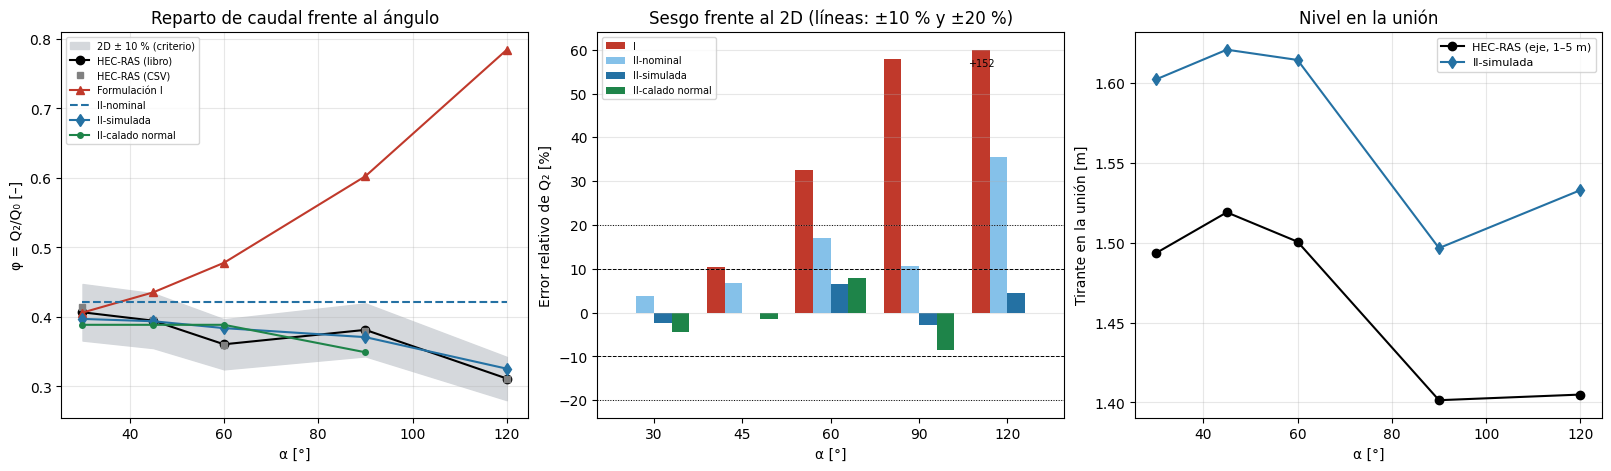

In [11]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.6), layout="constrained")
al = np.array(ANGULOS)
banda_lo, banda_hi = 0.9*R["φ 2D (libro)"], 1.1*R["φ 2D (libro)"]
ax[0].fill_between(al, banda_lo, banda_hi, color="#d5d8dc", label="2D ± 10 % (criterio)")
ax[0].plot(al, R["φ 2D (libro)"], "ko-", label="HEC-RAS (libro)")
ax[0].plot(al, R["φ 2D (CSV)"], "s", color="gray", ms=5, label="HEC-RAS (CSV)")
ax[0].plot(al, R["φ I"], "^-", color="#c0392b", label="Formulación I")
ax[0].plot(al, R["φ II-nominal"], "--", color="#2471a3", label="II-nominal")
ax[0].plot(al, R["φ II-simulada"], "d-", color="#2471a3", label="II-simulada")
ax[0].plot(al, R["φ II-calado normal"], "o-", color="#1e8449", ms=4, label="II-calado normal")
ax[0].set_xlabel("α [°]"); ax[0].set_ylabel("φ = Q₂/Q₀ [–]"); ax[0].set_title("Reparto de caudal frente al ángulo"); ax[0].grid(alpha=0.3); ax[0].legend(fontsize=7)

w = 0.2; xx = np.arange(len(al))
for j, (k, col) in enumerate((("I", "#c0392b"), ("II-nominal", "#85c1e9"), ("II-simulada", "#2471a3"), ("II-calado normal", "#1e8449"))):
    ax[1].bar(xx + (j - 1.5)*w, np.clip(R[f"ε(Q2) {k} [%]"].fillna(0), -60, 60), w, color=col, label=k)
    for xi, v in zip(xx, R[f"ε(Q2) {k} [%]"]):
        if abs(v) > 60: ax[1].text(xi + (j - 1.5)*w, 58*np.sign(v), f"{v:+.0f}", ha="center", va="top" if v > 0 else "bottom", fontsize=7)
for lim, ls in ((10, "--"), (20, ":")):
    ax[1].axhline(lim, color="k", lw=0.7, ls=ls); ax[1].axhline(-lim, color="k", lw=0.7, ls=ls)
ax[1].set_xticks(xx); ax[1].set_xticklabels(al); ax[1].set_xlabel("α [°]"); ax[1].set_ylabel("Error relativo de Q₂ [%]")
ax[1].set_title("Sesgo frente al 2D (líneas: ±10 % y ±20 %)"); ax[1].legend(fontsize=7); ax[1].grid(alpha=0.3, axis="y")

ax[2].plot(al, R["yJ 2D"], "ko-", label="HEC-RAS (eje, 1–5 m)")
ax[2].plot(al, R["yJ II-sim"], "d-", color="#2471a3", label="II-simulada")
ax[2].set_xlabel("α [°]"); ax[2].set_ylabel("Tirante en la unión [m]"); ax[2].set_title("Nivel en la unión"); ax[2].grid(alpha=0.3); ax[2].legend(fontsize=8)
plt.show()

### 5.3 Formulación I: ¿por qué no es comparable «tal cual» con el 2D?

La Formulación I fija el reparto **solo con la geometría** (condición de punto de estancamiento en la pared divisoria) y **no impone nivel común aguas abajo**: la presión en los dos ramales difiere por $\tfrac12(U_2^2-U_1^2)/g$. La hoja `resultados_tomson` informa esa diferencia relativa de calado, $(y_1-y_2)/y$. En el 2D los niveles de los dos ramales los fija la salida, de modo que el 2D no puede mostrar esa diferencia.

In [12]:
y_ref = 1.5
filas = []
for a in ANGULOS:
    t1, t2 = eje[a]["EJE_RAMAL1"], eje[a]["EJE_RAMAL2"]
    w1 = t1[(t1.Distancia_m >= 5) & (t1.Distancia_m <= 15)].NivelAgua_msnm.mean()
    w2 = t2[(t2.Distancia_m >= 5) & (t2.Distancia_m <= 15)].NivelAgua_msnm.mean()
    d_req = tom.loc[a, "(y1−y2)/y [%]"]/100*y_ref
    # b2 que necesitaria la Formulacion I para reproducir el phi del 2D (modo de diseno, solucion cerrada)
    mu_n = mu_diseno_I(0.75, R.loc[a, "φ 2D (libro)"], a)
    filas.append({"α [°]": a, "Δ nivel que exige la Formulación I [m]": d_req, "Δ nivel observado en el 2D (R1−R2) [m]": w1 - w2,
                  "b2 que reproduciría φ_2D en la Formulación I [m]": None if mu_n is None else mu_n*4.0})
dn = pd.DataFrame(filas).set_index("α [°]")
display(dn.style.format("{:+.3f}", subset=dn.columns[:2]).format("{:.2f}", subset=dn.columns[2], na_rep="no existe"))
print("(b2 real = 2.00 m;  Δ nivel de la Formulación I calculado como (y1−y2)/y × 1.5 m de tirante de referencia)")

,Δ nivel que exige la Formulación I [m],Δ nivel observado en el 2D (R1−R2) [m],b2 que reproduciría φ_2D en la Formulación I [m]
α [°],,,
30,+0.007,+0.002,2.00
45,+0.039,+0.003,1.61
60,+0.087,+0.001,0.64
90,+0.239,+0.006,no existe
120,+0.485,+0.001,no existe


(b2 real = 2.00 m;  Δ nivel de la Formulación I calculado como (y1−y2)/y × 1.5 m de tirante de referencia)


**Lectura.** (i) La Formulación I exige diferencias de nivel entre ramales que crecen con $\alpha$ (decímetros desde 90°), que **el 2D no muestra** (milímetros); (ii) predice que $\varphi$ **crece** con $\alpha$ ($0.41\to0.78$), mientras que $\varphi_{2D}$ decrece en conjunto ($0.41\to0.31$; esa tendencia del 2D está **confundida** con los cambios de configuración entre corridas, secciones 4.2 y 6.5); (iii) a partir de 90° **ningún ancho $b_2$** hace que la Formulación I alcance $\varphi_{2D}$ (la solución de diseño no existe). Todo es coherente con que la Formulación I describe un flujo ideal sin separación y sin condición de nivel aguas abajo, pero es una **explicación probable, no demostrada** aquí. Su coincidencia en 30° (error de $Q_2$ ≈ 0 %) no se sostiene al crecer $\alpha$.

**Consecuencia práctica.** La Formulación I sirve para **verificar el código** (Fases I y I bis) y para dibujar la red de flujo; **no** para predecir el reparto de este canal con salidas controladas por nivel, y su sesgo frente al 2D no es un error que se calibre con un parámetro.

## 6. Sensibilidad combinada con el sesgo (Formulación II-simulada)

Preguntas, con las **mismas 13 variables de la Fase III** y las mismas incertidumbres supuestas (ilustrativas, no medidas):

* **6.1** Elasticidades $E_{\varphi,p}$ **en la configuración simulada de cada ángulo**.
* **6.2** *Parámetro explicativo.* Para cerrar el sesgo $B=\varphi_{II}-\varphi_{2D}$ con **un solo** parámetro habría que cambiarlo $\Delta p^*=-B/(\partial\varphi/\partial p)$. Se compara con su incertidumbre $\sigma_p$: si $|\Delta p^*|/\sigma_p\lesssim 2$ el parámetro **puede** explicar el sesgo; si es mucho mayor, no.
* **6.3** *Banda paramétrica.* $\sigma_\varphi$ por propagación lineal (con Monte Carlo de comprobación, semilla fija) frente al sesgo: $z=B/\sigma_\varphi$.
* **6.4** *Calibración de $K$* (la pérdida local, que condensa lo que el 1D no ve): valor que anula el sesgo.

,30°,45°,60°,90°,120°
Q₀,-0.006,+0.019,+0.100,-0.056,+0.126
b1,-0.772,-0.797,-0.872,-0.751,-0.955
n1,+0.509,+0.527,+0.572,+0.480,+0.596
L1,+0.075,+0.072,+0.091,+0.052,+0.090
S1,-0.179,-0.191,-0.195,-0.188,-0.208
y_d1,+1.007,+1.128,+1.068,+0.912,+0.883
K1,+0.026,+0.027,+0.029,+0.034,+0.041
b2,+0.812,+0.807,+0.780,+0.863,+0.827
n2,-0.512,-0.512,-0.497,-0.545,-0.502
L2,-0.087,-0.076,-0.064,-0.104,-0.251


n/d: S₂ = 0 en la configuración simulada de 120° (elasticidad no definida para un parámetro nulo).


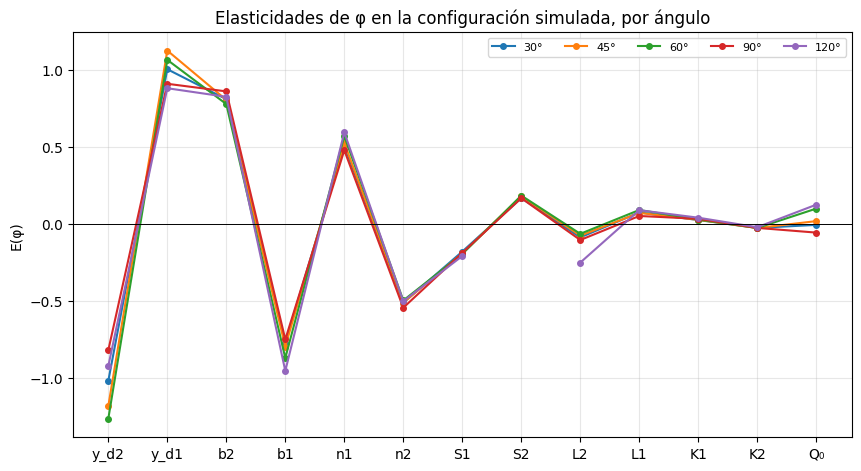

In [13]:
SIG = {"Q0": ("rel", 0.05), "b": ("rel", 0.02), "n": ("rel", 0.10), "L": ("rel", 0.02), "S": ("rel", 0.05),
       "yd": ("abs", 0.04), "K": ("abs", 0.10)}
def sigma_p(d, p):
    tipo, v = SIG[p[2]]
    return v*abs(valor(d, p)) if tipo == "rel" else v

def sens_angulo(a):
    d = cfg_a_datos(cfg.loc[a]); x = resolver(d)
    pars = [p for p in PARAMS if valor(d, p) != 0]              # una elasticidad respecto de un parametro nulo (S2 = 0) no esta definida
    E = sensibilidad_implicita(d, "analisis", pars, x)["phi"]
    E.index = [NOMBRES[i] for i in E.index]
    phi = x[1]/d["Q0"]
    dphi = {NOMBRES[p[0]]: E[NOMBRES[p[0]]]*phi/valor(d, p) for p in pars}
    sig = {NOMBRES[p[0]]: sigma_p(d, p) for p in pars}
    return d, x, phi, E, dphi, sig

SA = {a: sens_angulo(a) for a in ANGULOS}
Etab = pd.DataFrame({a: SA[a][3] for a in ANGULOS}).reindex([NOMBRES[p[0]] for p in PARAMS])
Etab.columns = [f"{a}°" for a in ANGULOS]
display(Etab.style.format("{:+.3f}", na_rep="n/d").background_gradient(cmap="RdBu_r", vmin=-1.5, vmax=1.5))
print("n/d: S₂ = 0 en la configuración simulada de 120° (elasticidad no definida para un parámetro nulo).")

fig, ax = plt.subplots(figsize=(8.5, 4.6), layout="constrained")
orden = Etab["45°"].abs().sort_values(ascending=False).index
for j, a in enumerate(ANGULOS):
    ax.plot(range(len(orden)), Etab.loc[orden, f"{a}°"].values, "o-", ms=4, label=f"{a}°")
ax.set_xticks(range(len(orden))); ax.set_xticklabels(orden); ax.axhline(0, color="k", lw=0.7)
ax.set_ylabel("E(φ)"); ax.set_title("Elasticidades de φ en la configuración simulada, por ángulo"); ax.grid(alpha=0.3); ax.legend(ncol=5, fontsize=8)
plt.show()

In [14]:
filas = []
for a in ANGULOS:
    d, x, phi, E, dphi, sig = SA[a]
    B = phi - R.loc[a, "φ 2D (libro)"]
    for nom in dphi:
        if abs(dphi[nom]) < 1e-12: continue
        dp = -B/dphi[nom]
        filas.append({"α [°]": a, "Parámetro": nom, "∂φ/∂p": dphi[nom], "Δp* para cerrar B": dp, "σ_p": sig[nom], "|Δp*|/σ_p": abs(dp)/sig[nom]})
shift = pd.DataFrame(filas)
R["B (II-sim) = φ − φ_2D"] = [SA[a][2] - R.loc[a, "φ 2D (libro)"] for a in ANGULOS]
for a in ANGULOS:
    s = shift[shift["α [°]"] == a].sort_values("|Δp*|/σ_p").head(4)
    print(f"α = {a:3d}°   B = {R.loc[a, 'B (II-sim) = φ − φ_2D']:+.4f}   parámetros con menor |Δp*|/σ:",
          "; ".join(f"{r['Parámetro']} ({r['Δp* para cerrar B']:+.3g}, {r['|Δp*|/σ_p']:.1f}σ)" for _, r in s.iterrows()))
pivote = shift.pivot(index="Parámetro", columns="α [°]", values="|Δp*|/σ_p").reindex([NOMBRES[p[0]] for p in PARAMS])
display(Markdown("**|Δp\\*|/σ_p**: cuántas desviaciones estándar habría que mover cada parámetro para cerrar el sesgo (≤ 2 → explicación plausible)"))
display(pivote.style.format("{:.1f}", na_rep="n/d").background_gradient(cmap="YlOrRd", vmin=0, vmax=6))

α =  30°   B = -0.0096   parámetros con menor |Δp*|/σ: n2 (-0.000845, 0.5σ); n1 (+0.00085, 0.5σ); y_d2 (-0.035, 0.9σ); y_d1 (+0.0357, 0.9σ)
α =  45°   B = -0.0008   parámetros con menor |Δp*|/σ: n1 (+6.92e-05, 0.0σ); n2 (-7.12e-05, 0.0σ); y_d2 (-0.0026, 0.1σ); y_d1 (+0.00273, 0.1σ)
α =  60°   B = +0.0233   parámetros con menor |Δp*|/σ: n1 (-0.00191, 1.1σ); n2 (+0.00219, 1.2σ); y_d2 (+0.0733, 1.8σ); y_d1 (-0.085, 2.1σ)
α =  90°   B = -0.0105   parámetros con menor |Δp*|/σ: n2 (-0.000932, 0.5σ); n1 (+0.000882, 0.6σ); y_d1 (+0.0434, 1.1σ); y_d2 (-0.0466, 1.2σ)
α = 120°   B = +0.0142   parámetros con menor |Δp*|/σ: n1 (-0.0011, 0.7σ); n2 (+0.00156, 0.9σ); y_d2 (+0.0604, 1.5σ); y_d1 (-0.0691, 1.7σ)


**|Δp\*|/σ_p**: cuántas desviaciones estándar habría que mover cada parámetro para cerrar el sesgo (≤ 2 → explicación plausible)

α [°],30,45,60,90,120
Parámetro,,,,,
Q₀,83.7,2.2,12.1,10.1,6.9
b1,1.6,0.1,3.5,1.9,2.3
n1,0.5,0.0,1.1,0.6,0.7
L1,16.0,1.4,33.3,27.0,24.2
S1,2.7,0.2,6.2,3.0,4.2
y_d1,0.9,0.1,2.1,1.1,1.7
K1,1.9,0.1,4.2,1.7,2.1
b2,1.5,0.1,3.9,1.6,2.6
n2,0.5,0.0,1.2,0.5,0.9


In [15]:
# 6.3 Banda parametrica: propagacion lineal + Monte Carlo (semilla fija) de la configuracion simulada de cada angulo
N_MC = 1500
filas = []
rng = np.random.default_rng(SEMILLA)
for a in ANGULOS:
    d0, x0_, phi0, E, dphi, sig = SA[a]
    sd_lin = np.sqrt(sum((dphi[k]*sig[k])**2 for k in dphi))
    pars = [p for p in PARAMS if valor(d0, p) != 0]
    phis = []
    for _ in range(N_MC):
        d2 = copy.deepcopy(d0)
        for p in pars:
            v = max(rng.normal(valor(d0, p), sigma_p(d0, p)), 1e-6)
            if p[1] is None: d2[p[2]] = v
            else: d2[p[1]][p[2]] = v
        try: phis.append(resolver(d2)[1]/d2["Q0"])
        except Exception: pass
    phis = np.array(phis); sd_mc = phis.std(ddof=1)
    B = phi0 - R.loc[a, "φ 2D (libro)"]
    filas.append({"α [°]": a, "φ II-sim": phi0, "σ_φ lineal": sd_lin, "σ_φ Monte Carlo": sd_mc, "MC/lineal − 1 [%]": 100*(sd_mc/sd_lin - 1),
                  "B = φ_II − φ_2D": B, "z = B/σ_φ(MC)": B/sd_mc, "|B| ≤ 2σ_φ": abs(B) <= 2*sd_mc, "Realizaciones": len(phis)})
banda = pd.DataFrame(filas).set_index("α [°]")
display(banda.style.format({"φ II-sim": "{:.4f}", "σ_φ lineal": "{:.4f}", "σ_φ Monte Carlo": "{:.4f}", "MC/lineal − 1 [%]": "{:+.1f}",
                            "B = φ_II − φ_2D": "{:+.4f}", "z = B/σ_φ(MC)": "{:+.2f}"}))

,φ II-sim,σ_φ lineal,σ_φ Monte Carlo,MC/lineal − 1 [%],B = φ_II − φ_2D,z = B/σ_φ(MC),|B| ≤ 2σ_φ,Realizaciones
α [°],,,,,,,,
30,0.3971,0.0348,0.0360,+3.4,-0.0096,-0.27,True,1500
45,0.3938,0.0358,0.0367,+2.3,-0.0008,-0.02,True,1500
60,0.3839,0.0360,0.0358,-0.4,+0.0233,+0.65,True,1500
90,0.3709,0.0325,0.0332,+2.0,-0.0105,-0.32,True,1500
120,0.3255,0.0307,0.0330,+7.6,+0.0142,+0.43,True,1500


,B,Cuál se calibra,K necesario,¿alcanzable (K ≤ 60)?
α [°],,,,
30,-0.0096,K1,0.40,True
45,-0.0008,K1,0.21,True
60,+0.0233,K2,0.74,True
90,-0.0105,K1,0.38,True
120,+0.0142,K2,0.66,True


Identificabilidad de K: φ al variar K2 de 0 a 1 (K2 = 0 → K2 = 1)
   30°: 0.4078 → 0.3638   (Δφ = -0.0440;  U_2D = 0.0078)
   45°: 0.4047 → 0.3600   (Δφ = -0.0446;  U_2D = 0.0078)
   60°: 0.3943 → 0.3515   (Δφ = -0.0428;  U_2D = 0.0078)
   90°: 0.3808 → 0.3398   (Δφ = -0.0410;  U_2D = 0.0078)
  120°: 0.3326 → 0.3022   (Δφ = -0.0304;  U_2D = 0.0078)


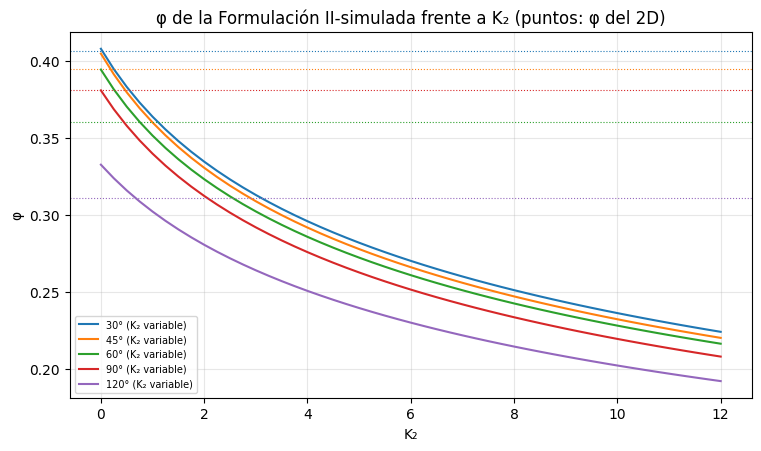

In [16]:
# 6.4 Calibracion de K: K que anula el sesgo (biseccion propia). Si el modelo da mas flujo al ramal 2 que el 2D (B > 0) se sube K2;
# si da menos (B < 0) se sube K1 (mas perdida en el ramal 1 desvia flujo al ramal 2).
def phi_con_K(a, K1, K2):
    d = cfg_a_datos(cfg.loc[a], K1=K1, K2=K2)
    return resolver(d)[1]/d["Q0"]

def K_calibrado(a, objetivo, K_max=60.0):
    B = phi_con_K(a, 0.2, 0.2) - objetivo
    if abs(B) < 1e-9: return ("K2", 0.2, True)
    quien = "K2" if B > 0 else "K1"
    f = (lambda k: phi_con_K(a, 0.2, k) - objetivo) if quien == "K2" else (lambda k: phi_con_K(a, k, 0.2) - objetivo)
    lo, hi = 0.0, K_max
    if f(lo)*f(hi) > 0:                                  # no hay cambio de signo: con ese K no se alcanza el objetivo
        return (quien, np.nan, False)
    for _ in range(80):
        mid = 0.5*(lo + hi)
        if f(lo)*f(mid) <= 0: hi = mid
        else: lo = mid
    return (quien, 0.5*(lo + hi), True)

filas = []
for a in ANGULOS:
    quien, K, ok = K_calibrado(a, R.loc[a, "φ 2D (libro)"])
    filas.append({"α [°]": a, "B": R.loc[a, "B (II-sim) = φ − φ_2D"], "Cuál se calibra": quien, "K necesario": K, "¿alcanzable (K ≤ 60)?": ok})
kcal = pd.DataFrame(filas).set_index("α [°]")
display(kcal.style.format({"B": "{:+.4f}", "K necesario": "{:.2f}"}, na_rep="no alcanzable"))
rango = {a: (phi_con_K(a, 0.2, 0.0), phi_con_K(a, 0.2, 1.0)) for a in ANGULOS}
print("Identificabilidad de K: φ al variar K2 de 0 a 1 (K2 = 0 → K2 = 1)")
for a in ANGULOS:
    print(f"  {a:3d}°: {rango[a][0]:.4f} → {rango[a][1]:.4f}   (Δφ = {rango[a][1] - rango[a][0]:+.4f};  U_2D = {U_PHI_2D:.4f})")
Ks = np.linspace(0, 12, 49)
fig, ax = plt.subplots(figsize=(7.5, 4.4), layout="constrained")
for a in ANGULOS:
    ax.plot(Ks, [phi_con_K(a, 0.2, k) for k in Ks], label=f"{a}° (K₂ variable)")
    ax.axhline(R.loc[a, "φ 2D (libro)"], ls=":", lw=0.8, color=ax.lines[-1].get_color())
ax.set_xlabel("K₂"); ax.set_ylabel("φ"); ax.set_title("φ de la Formulación II-simulada frente a K₂ (puntos: φ del 2D)"); ax.grid(alpha=0.3); ax.legend(fontsize=7)
plt.show()

In [17]:
# 6.5 Descomposicion de la diferencia nominal -> 2D en dos pasos
filas = []
for a in ANGULOS:
    c = cfg.loc[a]
    d_p1 = copy.deepcopy(datos); d_p1["ramal1"]["n"] = c["n1"]; d_p1["ramal2"].update(n=c["n2"], S=c["S2"])      # solo rugosidad y pendiente simuladas
    phi_nom = x_II[1]/Q0; phi_p1 = resolver(d_p1)[1]/Q0; phi_sim = R.loc[a, "φ II-simulada"]; phi2 = R.loc[a, "φ 2D (libro)"]
    filas.append({"α [°]": a, "φ 2D": phi2, "II-nominal − 2D": phi_nom - phi2,
                  "Paso 1: n1, S2 simulados": phi_p1 - phi_nom, "Paso 2: calados de salida del 2D": phi_sim - phi_p1,
                  "II-simulada − 2D (sesgo restante)": phi_sim - phi2})
desc = pd.DataFrame(filas).set_index("α [°]")
display(desc.style.format("{:+.4f}"))

# 6.6 Sensibilidad estructural: ley de friccion (el 1D usa P = b + 2y; el 2D usa R ~ h, sin friccion de pared)
_pf_orig = pendiente_friccion
def pendiente_friccion_ancha(n, Q, b, y):
    Sf = n**2*Q**2/(b**2*y**(10/3))
    return Sf, 2*Sf/Q, -10/3*Sf/y, -2*Sf/b
filas = []
try:
    for a in ANGULOS:
        d_sim = cfg_a_datos(cfg.loc[a])
        pendiente_friccion = pendiente_friccion_ancha
        x_w = resolver(d_sim)
        pendiente_friccion = _pf_orig
        filas.append({"α [°]": a, "φ 2D": R.loc[a, "φ 2D (libro)"], "φ (P = b+2y)": R.loc[a, "φ II-simulada"], "φ (R = y)": x_w[1]/Q0,
                      "yJ 2D": R.loc[a, "yJ 2D"], "yJ (P = b+2y)": R.loc[a, "yJ II-sim"], "yJ (R = y)": x_w[2] - 100.0})
finally:
    pendiente_friccion = _pf_orig
ley = pd.DataFrame(filas).set_index("α [°]")
ley["Δ yJ (P=b+2y)"] = ley["yJ (P = b+2y)"] - ley["yJ 2D"]; ley["Δ yJ (R=y)"] = ley["yJ (R = y)"] - ley["yJ 2D"]
display(ley.style.format("{:+.4f}"))

,φ 2D,II-nominal − 2D,"Paso 1: n1, S2 simulados",Paso 2: calados de salida del 2D,II-simulada − 2D (sesgo restante)
α [°],,,,,
30,+0.4067,+0.0150,+0.0247,-0.0492,-0.0096
45,+0.3946,+0.0270,+0.0247,-0.0525,-0.0008
60,+0.3606,+0.0610,+0.0247,-0.0624,+0.0233
90,+0.3814,+0.0403,+0.0000,-0.0507,-0.0105
120,+0.3113,+0.1103,-0.0723,-0.0238,+0.0142


,φ 2D,φ (P = b+2y),φ (R = y),yJ 2D,yJ (P = b+2y),yJ (R = y),Δ yJ (P=b+2y),Δ yJ (R=y)
α [°],,,,,,,,
30,+0.4067,+0.3971,+0.4261,+1.4935,+1.6023,+1.4469,+0.1088,-0.0466
45,+0.3946,+0.3938,+0.4173,+1.5190,+1.6209,+1.4713,+0.1019,-0.0477
60,+0.3606,+0.3839,+0.3881,+1.5006,+1.6144,+1.4640,+0.1138,-0.0366
90,+0.3814,+0.3709,+0.4132,+1.4014,+1.4966,+1.3483,+0.0953,-0.0530
120,+0.3113,+0.3255,+0.3190,+1.4049,+1.5329,+1.3869,+0.1280,-0.0180


## 7. Veredicto y conclusiones

Las cifras de esta sección salen de las tablas anteriores (se calculan en las celdas, no están escritas a mano).

In [18]:
DEFECTOS_2D = {30: "n del ramal 1 = 0.018 (debía ser 0.015)", 45: "n del ramal 1 = 0.018 (debía ser 0.015)",
               60: "n del ramal 1 = 0.018 (debía ser 0.015)",
               90: "≈ ¼ superior de la franja del canal con n = 0.018 (efecto pequeño, no cuantificado)",
               120: "fondo plano en el ramal 2 (debía ser S₂ = 0.001)"}

def decision(a):
    clases = [clase_Q2n(R.loc[a, "ε(Q2) II-simulada [%]"]), clase_Q2n(R.loc[a, "ε(Q2) II-calado normal [%]"])]
    peor = "NO ACEPTABLE" if "NO ACEPTABLE" in clases else ("MARGINAL" if "MARGINAL" in clases else "ACEPTABLE")
    return peor

VG = pd.DataFrame({
    "ε(Q2) II-calado normal [%]": R["ε(Q2) II-calado normal [%]"],
    "ε(Q2) II-simulada [%]": R["ε(Q2) II-simulada [%]"],
    "Reparto (peor de las dos)": [decision(a) for a in ANGULOS],
    "Nivel en la unión [m]": R["Δ yJ II-sim [m]"], "Nivel": R["Δ yJ II-sim [m]"].map(clase_y),
    "Defecto del 2D (generador v1)": [DEFECTOS_2D[a] for a in ANGULOS]})
display(VG.style.format({"ε(Q2) II-calado normal [%]": "{:+.1f}", "ε(Q2) II-simulada [%]": "{:+.1f}", "Nivel en la unión [m]": "{:+.3f}"}, na_rep="n/d"))

n_ac = [a for a in ANGULOS if VG.loc[a, "Reparto (peor de las dos)"] == "ACEPTABLE"]
emax_sim = R["ε(Q2) II-simulada [%]"].abs().max(); emax_yn = R["ε(Q2) II-calado normal [%]"].abs().max()
d_nom = R.loc[agud, "ε(Q2) II-nominal [%]"]
paso2 = desc["Paso 2: calados de salida del 2D"]
K_rng = max(abs(rango[a][1] - rango[a][0]) for a in ANGULOS)
txt = ""
txt += f"- **Reparto, Formulación II con la configuración simulada:** error de Q₂ ≤ {emax_sim:.1f} % con calados de salida del 2D (30°–120°) y ≤ {emax_yn:.1f} % con calado normal, que no usa ningún dato del 2D (30°–90°). Reparto ACEPTABLE (≤ 10 %) en {n_ac}. MAE de φ: {mae90['II-simulada']:.3f} y {mae90['II-calado normal']:.3f} (30°–90°).\n"
txt += f"- **Con los datos nominales del informe**, el error de Q₂ frente al 2D es {', '.join(f'{v:+.1f} %' for v in d_nom)} (30°–90°) y {R.loc[120, 'ε(Q2) II-nominal [%]']:+.1f} % en 120°. **No es el sesgo del modelo**: la configuración del 2D difiere (n del ramal 1, fondo en 120°) y, sobre todo, **la salida**: el informe fija y_d = 1.6 / 1.4 m y el 2D tiene ≈ 1.5 / 1.5 m (calado normal). Solo el cambio de salida mueve φ en {paso2.min():+.3f} a {paso2.max():+.3f}.\n"
txt += f"- **Nivel en la unión:** el 1D sobreestima el tirante entre {R['Δ yJ II-sim [m]'].min():+.3f} y {R['Δ yJ II-sim [m]'].max():+.3f} m (marginal en 4 de 5 ángulos, siempre con el mismo signo). Con fricción de pared ancha (R = y) el error pasa a {ley['Δ yJ (R=y)'].min():+.3f} … {ley['Δ yJ (R=y)'].max():+.3f} m: el 2D queda **entre** las dos leyes de fricción; es una diferencia **estructural 1D–2D** y no un error de la unión.\n"
txt += f"- **Formulación I:** error de Q₂ de {R.loc[30, 'ε(Q2) I [%]']:+.1f} % en 30°, {R.loc[45, 'ε(Q2) I [%]']:+.0f} % en 45°, {R.loc[90, 'ε(Q2) I [%]']:+.0f} % en 90° y {R.loc[120, 'ε(Q2) I [%]']:+.0f} % en 120°; tendencia con α opuesta; no calibrable (sección 5.3). **No aceptable** como predictor del reparto de este canal.\n"
txt += f"- **Sensibilidad y sesgo:** φ responde sobre todo a los calados de salida (|E| ≈ {Etab.loc['y_d1', '45°']:.1f}), al ancho (|E| ≈ {abs(Etab.loc['b1', '45°']):.1f}) y a la rugosidad (|E| ≈ {Etab.loc['n1', '45°']:.1f}); a la pérdida local, casi nada (|E(K)| ≈ {abs(Etab.loc['K1', '45°']):.2f}). Cerrar el sesgo exigiría mover n₁ o n₂ ≈ {shift[shift['Parámetro'] == 'n1']['|Δp*|/σ_p'].max():.1f} σ como máximo: está **dentro de la incertidumbre** de los parámetros; en la banda paramétrica supuesta (σ_φ ≈ {banda['σ_φ Monte Carlo'].mean():.3f}) el sesgo cabe en ±2σ en {[a for a in ANGULOS if banda.loc[a, '|B| ≤ 2σ_φ']]}. Esa banda es ancha por las σ supuestas: significa «no distinguible de la incertidumbre de parámetros», no «el modelo es exacto».\n"
res_K = U_PHI_2D/np.mean([abs(rango[a][1] - rango[a][0]) for a in ANGULOS])
txt += f"- **Pérdida local K:** la elasticidad es baja (|E(K)| ≈ {abs(Etab.loc['K1', '45°']):.2f}) pero su rango plausible es amplio: K de 0 a 1 mueve φ hasta {K_rng:.3f}. Los K que anulan el sesgo valen {kcal['K necesario'].min():.2f} a {kcal['K necesario'].max():.2f} (nominal 0.2). Con el ruido del 2D ({U_PHI_2D:.3f}) K queda determinado solo a ±{res_K:.2f}, y las corridas están confundidas con la configuración, de modo que **no** se debe interpretar K(α) como propiedad de la unión.\n"
display(Markdown(txt))

,ε(Q2) II-calado normal [%],ε(Q2) II-simulada [%],Reparto (peor de las dos),Nivel en la unión [m],Nivel,Defecto del 2D (generador v1)
α [°],,,,,,
30,-4.4,-2.3,ACEPTABLE,+0.109,MARGINAL,n del ramal 1 = 0.018 (debía ser 0.015)
45,-1.5,-0.2,ACEPTABLE,+0.102,MARGINAL,n del ramal 1 = 0.018 (debía ser 0.015)
60,+7.8,+6.5,ACEPTABLE,+0.114,MARGINAL,n del ramal 1 = 0.018 (debía ser 0.015)
90,-8.5,-2.7,ACEPTABLE,+0.095,ACEPTABLE,"≈ ¼ superior de la franja del canal con n = 0.018 (efecto pequeño, no cuantificado)"
120,n/d,+4.6,ACEPTABLE,+0.128,MARGINAL,fondo plano en el ramal 2 (debía ser S₂ = 0.001)


- **Reparto, Formulación II con la configuración simulada:** error de Q₂ ≤ 6.5 % con calados de salida del 2D (30°–120°) y ≤ 8.5 % con calado normal, que no usa ningún dato del 2D (30°–90°). Reparto ACEPTABLE (≤ 10 %) en [30, 45, 60, 90, 120]. MAE de φ: 0.011 y 0.021 (30°–90°).
- **Con los datos nominales del informe**, el error de Q₂ frente al 2D es +3.7 %, +6.8 %, +16.9 %, +10.6 % (30°–90°) y +35.4 % en 120°. **No es el sesgo del modelo**: la configuración del 2D difiere (n del ramal 1, fondo en 120°) y, sobre todo, **la salida**: el informe fija y_d = 1.6 / 1.4 m y el 2D tiene ≈ 1.5 / 1.5 m (calado normal). Solo el cambio de salida mueve φ en -0.062 a -0.024.
- **Nivel en la unión:** el 1D sobreestima el tirante entre +0.095 y +0.128 m (marginal en 4 de 5 ángulos, siempre con el mismo signo). Con fricción de pared ancha (R = y) el error pasa a -0.053 … -0.018 m: el 2D queda **entre** las dos leyes de fricción; es una diferencia **estructural 1D–2D** y no un error de la unión.
- **Formulación I:** error de Q₂ de -0.1 % en 30°, +10 % en 45°, +58 % en 90° y +152 % en 120°; tendencia con α opuesta; no calibrable (sección 5.3). **No aceptable** como predictor del reparto de este canal.
- **Sensibilidad y sesgo:** φ responde sobre todo a los calados de salida (|E| ≈ 1.1), al ancho (|E| ≈ 0.8) y a la rugosidad (|E| ≈ 0.5); a la pérdida local, casi nada (|E(K)| ≈ 0.03). Cerrar el sesgo exigiría mover n₁ o n₂ ≈ 1.1 σ como máximo: está **dentro de la incertidumbre** de los parámetros; en la banda paramétrica supuesta (σ_φ ≈ 0.035) el sesgo cabe en ±2σ en [30, 45, 60, 90, 120]. Esa banda es ancha por las σ supuestas: significa «no distinguible de la incertidumbre de parámetros», no «el modelo es exacto».
- **Pérdida local K:** la elasticidad es baja (|E(K)| ≈ 0.03) pero su rango plausible es amplio: K de 0 a 1 mueve φ hasta 0.045. Los K que anulan el sesgo valen 0.21 a 0.74 (nominal 0.2). Con el ruido del 2D (0.008) K queda determinado solo a ±0.19, y las corridas están confundidas con la configuración, de modo que **no** se debe interpretar K(α) como propiedad de la unión.


### Qué se concluye y qué no

* **Se concluye:** con la misma configuración y la misma condición de salida, la Formulación II reproduce el reparto del 2D con un error de $Q_2$ dentro del rango aceptable propuesto (≤ 10 %), para todos los ángulos; el sesgo es del orden del ruido de medición del 2D más la incertidumbre de parámetros. El nivel en la unión queda marginal por una diferencia de ley de fricción 1D–2D, no por la unión.
* **No se concluye** que el modelo 1D capture (o deje de capturar) el efecto del ángulo: el 2D tal como se corrió **no aísla** ese efecto, porque entre ángulos cambiaron la rugosidad del ramal 1, el fondo del ramal 2 (120°) y los calados de salida, y φ es mucho más sensible a esas variables que a la unión. La tendencia de $\varphi_{2D}$ con $\alpha$ está confundida con esos cambios.
* **No se concluye** que el 2D esté convergido en malla ni que use las ecuaciones adecuadas (no hay datos); tampoco que la condición de salida sea calado normal más allá de lo que muestran los perfiles.

**Límites.**

1. Una sola malla por ángulo y plan desconocido (borde, ecuaciones, tamaño de celda, viscosidad turbulenta). Las capas límite de ≈ 1 m en cada pared indican resolución gruesa. La comparación es 1D–2D, no 1D–realidad.
2. El 2D de 30°, 45°, 60°, 90° y 120° se corrió con el generador v1 (defectos de la tabla de la sección 7). El 1D se ajustó a lo simulado para poder juzgar al modelo, pero los 2D deben **repetirse con el generador v2**.
3. La condición de salida se dedujo de los perfiles, no del plan de HEC-RAS; las variantes «II-simulada» (circular en parte) y «II-calado normal» (no circular) la acotan.
4. Las incertidumbres de la sección 6 son las supuestas en la Fase III (datos hipotéticos); las conclusiones sobre la banda paramétrica dependen de ellas, el orden de las elasticidades no.
5. Sensibilidad local y de parámetros independientes; no hay análisis global (Sobol).
6. Criterios de aceptación **propuestos**, no normativos; confirmar con el docente.

**Pendiente (para cerrar la etapa de comparación).**

* Repetir el 2D de los cinco ángulos con el generador v2, **con calado fijo en las salidas** (101.44 / 101.25 m, archivo `bc_salida_stage.csv` del generador) y con la misma configuración en todos; así cualquier variación de φ con α es del nudo.
* Tres mallas (0.50, 0.25 y 0.125 m) al menos para 45° y 90°, y balance de masa del plan.
* Confirmar los criterios con el docente; después, la Discusión y la bibliografía (necesaria la *Hydraulic Reference Manual* de HEC-RAS).

## 8. Referencias

* Chaudhry, M. H. (2008). *Open-Channel Flow* (2.ª ed.). Springer.
* Ghostine, R., Mose, R., Vazquez, J., Ghenaim, A., y Grégoire, C. (2012). *Journal of Hydraulic Research, 50*(2), 164–170. (Combinación de flujos en confluencias; verificar autores y título antes de citar.)
* Kesserwani, G., et al. (2010). *Journal of Hydraulic Engineering, 136*(9), 662–668. https://doi.org/10.1061/(ASCE)HY.1943-7900.0000222 (verificar autores y título antes de citar.)
* Milne-Thomson, L. M. (1968). *Theoretical Hydrodynamics* (5.ª ed.). Dover.
* US Army Corps of Engineers, Hydrologic Engineering Center. *HEC-RAS User's Manual* v6.6; *Hydraulic Reference Manual* (pendiente de obtener).